In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
with open("Scores.csv", "r", encoding="utf-8", errors="replace") as f:
    for i in range(10):
        print(f"{i + 1}: {f.readline()!r}")

1: '"";"student_id";"gender";"parental.level.of.education";"subject";"score"\n'
2: '"1";"id_001";"female";"high school";"math";23\n'
3: '"2";"id_001";"female";"high school";"language";40\n'
4: '"3";"id_002";"female";"high school";"math";68\n'
5: '"4";"id_002";"female";"high school";"language";80,5\n'
6: '"5";"id_003";"male";"high school";"math";82\n'
7: '"6";"id_003";"male";"high school";"language";81\n'
8: '"7";"id_004";"female";"high school";"math";58\n'
9: '"8";"id_004";"female";"high school";"language";60,5\n'
10: '"9";"id_005";"female";"high school";"math";60\n'


In [33]:
scores_df = pd.read_csv(
    "Scores.csv",
    sep=";",  # Columns are separated by semicolons
    decimal=",",  # Numbers like 80,5 become floats (80.5)
    index_col=0,  # Uses the first "" column as the index instead of an extra column
)

In [34]:
scores_df.head(20)

,student_id,gender,parental.level.of.education,subject,score
1,id_001,female,high school,math,23.0
2,id_001,female,high school,language,40.0
3,id_002,female,high school,math,68.0
4,id_002,female,high school,language,80.5
5,id_003,male,high school,math,82.0
6,id_003,male,high school,language,81.0
7,id_004,female,high school,math,58.0
8,id_004,female,high school,language,60.5
9,id_005,female,high school,math,60.0
10,id_005,female,high school,language,69.0


In [35]:
scores_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 972 entries, 1 to 972
Data columns (total 5 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   student_id                   972 non-null    str    
 1   gender                       972 non-null    str    
 2   parental.level.of.education  972 non-null    str    
 3   subject                      972 non-null    str    
 4   score                        972 non-null    float64
dtypes: float64(1), str(4)
memory usage: 68.7 KB


In [36]:
pivoted_df = (
    scores_df.pivot(
        index=["student_id", "gender", "parental.level.of.education"],
        columns="subject",
        values="score",
    )
    .reset_index()
    .rename_axis(None, axis=1)
)

In [41]:
scores_df.head()

,student_id,gender,parental.level.of.education,subject,score
1,id_001,female,high school,math,23.0
2,id_001,female,high school,language,40.0
3,id_002,female,high school,math,68.0
4,id_002,female,high school,language,80.5
5,id_003,male,high school,math,82.0


In [46]:
pivoted_df.head(50)

,student_id,gender,parental.level.of.education,language,math
0,id_001,female,high school,40.0,23.0
1,id_002,female,high school,80.5,68.0
2,id_003,male,high school,81.0,82.0
3,id_004,female,high school,60.5,58.0
4,id_005,female,high school,69.0,60.0
5,id_006,male,high school,62.5,79.0
6,id_007,female,high school,83.0,81.0
7,id_008,female,high school,40.5,34.0
8,id_009,male,high school,75.5,84.0
9,id_010,female,high school,73.0,67.0


In [38]:
pivoted_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 486 entries, 0 to 485
Data columns (total 5 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   student_id                   486 non-null    str    
 1   gender                       486 non-null    str    
 2   parental.level.of.education  486 non-null    str    
 3   language                     486 non-null    float64
 4   math                         486 non-null    float64
dtypes: float64(2), str(3)
memory usage: 31.7 KB


In [39]:
print("Original dataset:", scores_df.shape)
print("Transformed dataset:", pivoted_df.shape)
print("Unique students:", scores_df["student_id"].nunique())

Original dataset: (972, 5)
Transformed dataset: (486, 5)
Unique students: 486


In [42]:
print("Missing values in original dataset:")
print(scores_df.isnull().sum())

print("\nMissing values in transformed dataset:")
print(pivoted_df.isnull().sum())

Missing values in original dataset:
student_id                     0
gender                         0
parental.level.of.education    0
subject                        0
score                          0
dtype: int64

Missing values in transformed dataset:
student_id                     0
gender                         0
parental.level.of.education    0
language                       0
math                           0
dtype: int64


In [43]:
print("Duplicate rows:", scores_df.duplicated().sum())

print(
    "Duplicate student-subject combinations:",
    scores_df.duplicated(
        subset=["student_id", "subject"]
    ).sum()
)

Duplicate rows: 0
Duplicate student-subject combinations: 0


In [51]:
print("Gender categories:")
print(scores_df["gender"].value_counts())

print("\nSubject categories:")
print(scores_df["subject"].value_counts())

print("\nParental education categories:")
print(scores_df["parental.level.of.education"].value_counts())

Gender categories:
gender
female    490
male      482
Name: count, dtype: int64

Subject categories:
subject
math        486
language    486
Name: count, dtype: int64

Parental education categories:
parental.level.of.education
associate's degree    354
high school           312
bachelor's degree     188
master's degree       118
Name: count, dtype: int64


In [47]:
print("Minimum score:", scores_df["score"].min())
print("Maximum score:", scores_df["score"].max())

print("\nScore summary:")
print(scores_df["score"].describe())

Minimum score: 19.5
Maximum score: 100.0

Score summary:
count    972.000000
mean      67.690844
std       14.804105
min       19.500000
25%       57.000000
50%       68.000000
75%       78.000000
max      100.000000
Name: score, dtype: float64


In [48]:
pivoted_df.head(10)

,student_id,gender,parental.level.of.education,language,math
0,id_001,female,high school,40.0,23.0
1,id_002,female,high school,80.5,68.0
2,id_003,male,high school,81.0,82.0
3,id_004,female,high school,60.5,58.0
4,id_005,female,high school,69.0,60.0
5,id_006,male,high school,62.5,79.0
6,id_007,female,high school,83.0,81.0
7,id_008,female,high school,40.5,34.0
8,id_009,male,high school,75.5,84.0
9,id_010,female,high school,73.0,67.0


In [49]:
pivoted_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 486 entries, 0 to 485
Data columns (total 5 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   student_id                   486 non-null    str    
 1   gender                       486 non-null    str    
 2   parental.level.of.education  486 non-null    str    
 3   language                     486 non-null    float64
 4   math                         486 non-null    float64
dtypes: float64(2), str(3)
memory usage: 31.7 KB


In [52]:
# Count unique students, not individual subject records

print("Total students:", pivoted_df["student_id"].nunique())

print("\nGender distribution:")
print(pivoted_df["gender"].value_counts())

print("\nParental education distribution:")
print(
    pivoted_df["parental.level.of.education"]
    .value_counts()
)

print("\nSubject distribution in original dataset:")
print(scores_df["subject"].value_counts())

Total students: 486

Gender distribution:
gender
female    245
male      241
Name: count, dtype: int64

Parental education distribution:
parental.level.of.education
associate's degree    177
high school           156
bachelor's degree      94
master's degree        59
Name: count, dtype: int64

Subject distribution in original dataset:
subject
math        486
language    486
Name: count, dtype: int64


In [53]:
education_distribution = (
    pivoted_df["parental.level.of.education"]
    .value_counts()
    .to_frame(name="students")
)

education_distribution["percentage"] = (
    education_distribution["students"] / len(pivoted_df)
) * 100

education_distribution

,students,percentage
parental.level.of.education,,
associate's degree,177,36.419753
high school,156,32.098765
bachelor's degree,94,19.341564
master's degree,59,12.139918


Are there differences in Mathematics and Language scores between male and female students?
Do scores differ across parental education levels, and which groups differ?

In [55]:
score_columns = ["math", "language"]

overall_summary = pivoted_df[score_columns].describe().T

overall_summary

,count,mean,std,min,25%,50%,75%,max
math,486.0,66.380658,15.054580,23.0,56.0,66.0,77.75,100.0
language,486.0,69.001029,14.446257,19.5,58.0,70.0,78.50,100.0


In [56]:
gender_summary = (
    pivoted_df
    .groupby("gender")[["math", "language"]]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

gender_summary

math                      language                     
       count   mean median    std    count   mean median    std
gender                                                         
female   245  63.86   64.0  15.26      245  73.00   73.0  14.01
male     241  68.95   70.0  14.43      241  64.93   65.5  13.75

In [57]:
education_order = [
    "high school",
    "associate's degree",
    "bachelor's degree",
    "master's degree"
]

pivoted_df["parental.level.of.education"] = pd.Categorical(
    pivoted_df["parental.level.of.education"],
    categories=education_order,
    ordered=True
)

In [58]:
education_summary = (
    pivoted_df
    .groupby(
        "parental.level.of.education",
        observed=False
    )[["math", "language"]]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

education_summary

math                      language                \
                            count   mean median    std    count   mean median   
parental.level.of.education                                                     
high school                   156  62.24   63.0  14.04      156  63.53   65.0   
associate's degree            177  67.81   66.0  15.24      177  70.02   72.0   
bachelor's degree              94  68.44   67.0  15.05       94  72.06   73.0   
master's degree                59  69.75   73.0  15.15       59  75.53   76.0   

                                    
                               std  
parental.level.of.education         
high school                  13.40  
associate's degree           14.21  
bachelor's degree            14.27  
master's degree              13.55

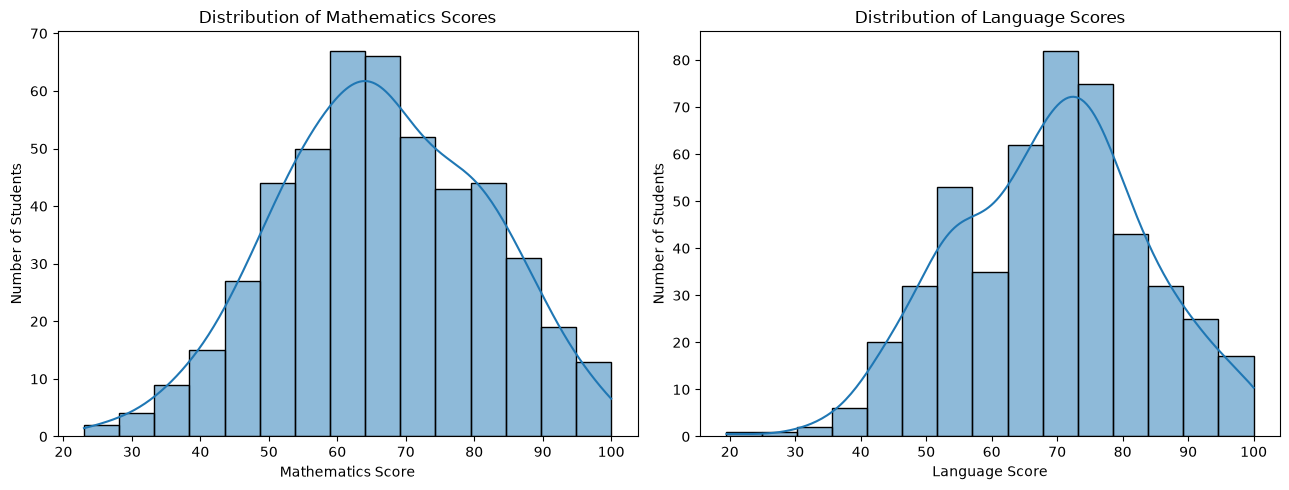

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=pivoted_df,
    x="math",
    bins=15,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Mathematics Scores")
axes[0].set_xlabel("Mathematics Score")
axes[0].set_ylabel("Number of Students")

sns.histplot(
    data=pivoted_df,
    x="language",
    bins=15,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution of Language Scores")
axes[1].set_xlabel("Language Score")
axes[1].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()


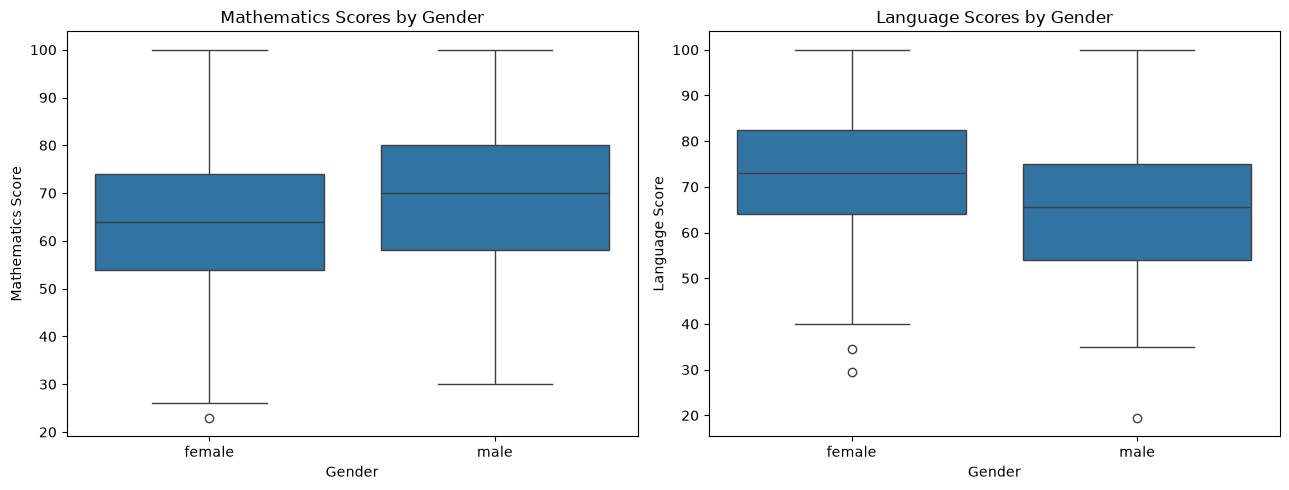

In [66]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=pivoted_df,
    x="gender",
    y="math",
    ax=axes[0]
)
axes[0].set_title("Mathematics Scores by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Mathematics Score")

sns.boxplot(
    data=pivoted_df,
    x="gender",
    y="language",
    ax=axes[1]
)
axes[1].set_title("Language Scores by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Language Score")

plt.tight_layout()
plt.show()


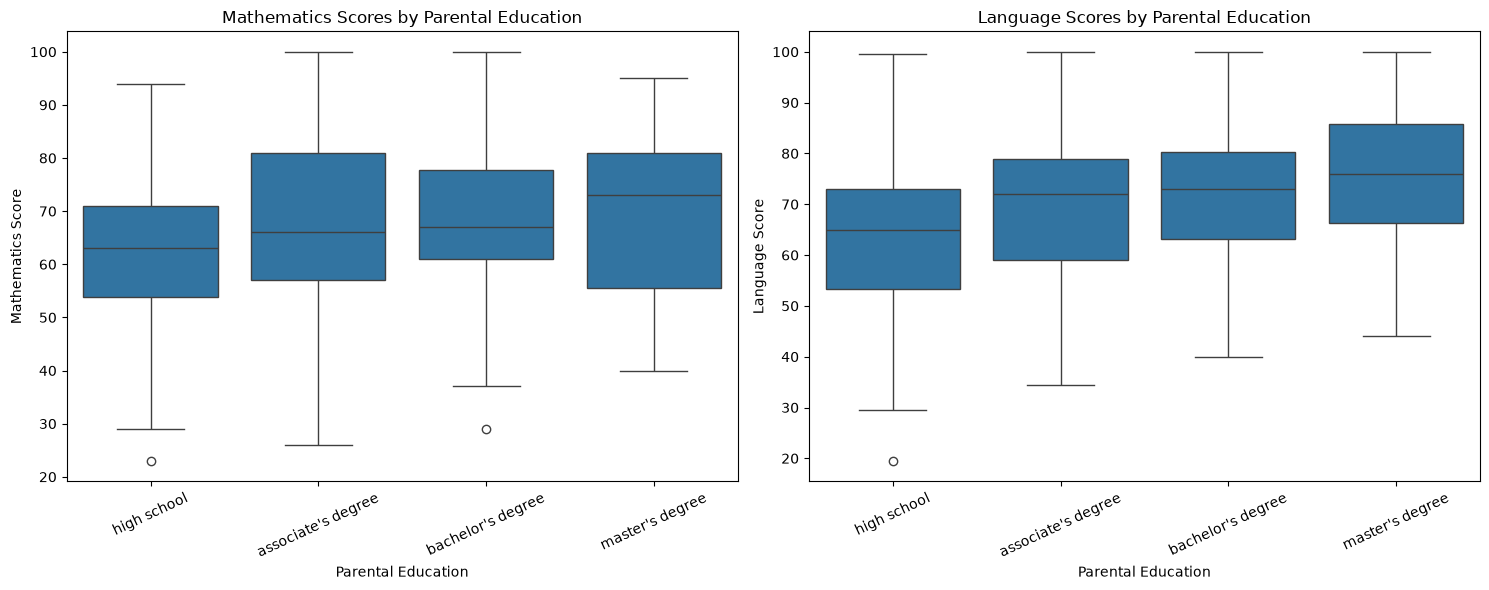

In [67]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(
    data=pivoted_df,
    x="parental.level.of.education",
    y="math",
    order=education_order,
    ax=axes[0]
)
axes[0].set_title("Mathematics Scores by Parental Education")
axes[0].set_xlabel("Parental Education")
axes[0].set_ylabel("Mathematics Score")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=pivoted_df,
    x="parental.level.of.education",
    y="language",
    order=education_order,
    ax=axes[1]
)
axes[1].set_title("Language Scores by Parental Education")
axes[1].set_xlabel("Parental Education")
axes[1].set_ylabel("Language Score")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()
